# Завдання 3. Структура графа і роль хабів

**Пункт 3 ТЗ.** Дослідити вплив структури графа (щільність, кластерність, довжина шляхів, вузли з великим степенем) на поширення релевантності; встановити, як нормування за степенем змінює роль хабів.

Параметри: PPR з α = 0.15 і теплове ядро з t = 5.67 = (1 − α)/α. За п. 2 при цих значеннях моделі дають близьке ранжування. Частину 3.3 повторюємо при α = 0.05: тоді маса йде далі, і роль хабів сильніша.

**Хаб** — вузол із верхнього 1% за степенем. Через нічиї на межі фактична частка може бути більшою; її наведено в таблиці властивостей. Для графів з однаковими степенями (WS p = 0) хаби не визначені.

**Нормування:**
- (а) π_i/d_i — основне;
- (б) π_i/√d_i — те саме ранжування, що дає поширення з симетричною матрицею D^(−1/2)·W·D^(−1/2), бо x_i = √d_q·π_i/√d_i (тест `tests/test_normalization.py`).

In [1]:
from pathlib import Path
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kendalltau

from reldiff.api import rank, spectrum
from reldiff import graphs as G
from reldiff import metaqa as MQ
from reldiff import analytic as A

FIG = Path("../figures"); RES = Path("../results")
N, N_SEEDS = 1000, 20
ALPHA, T = 0.15, (1 - 0.15) / 0.15

def lcc(g):
    # найбільша компонента зв'язності (копія)
    return g.subgraph(max(nx.connected_components(g), key=len)).copy()

GR, INFO = {}, {}
# Щільність: ER з різним середнім степенем; для рідких — найбільша компонента
for dm in (4, 6, 10, 20, 40):
    g0 = G.erdos_renyi(N, dm / (N - 1), seed=100 + dm, connected=False)
    g = lcc(g0)
    GR[f"ER ⟨d⟩={dm}"] = g
    INFO[f"ER ⟨d⟩={dm}"] = dict(сімейство="щільність (ER)", n_до=N, ребер_до=g0.number_of_edges())
# Кластерність і довжина шляхів разом: WS
for p in (0.0, 0.01, 0.05, 0.1, 0.3, 1.0):
    GR[f"WS p={p}"] = G.watts_strogatz(N, 10, p, seed=200)
    INFO[f"WS p={p}"] = dict(сімейство="кластерність+шляхи (WS)", n_до=N, ребер_до=GR[f"WS p={p}"].number_of_edges())
# Кластерність при сталих степенях: Холме–Кім
for pt in (0.0, 0.3, 0.6, 0.9):
    GR[f"ХК p_Δ={pt}"] = nx.powerlaw_cluster_graph(N, 5, pt, seed=300)
    INFO[f"ХК p_Δ={pt}"] = dict(сімейство="кластерність (Холме–Кім)", n_до=N, ребер_до=GR[f"ХК p_Δ={pt}"].number_of_edges())
# Хаби: конфігураційна модель зі степеневим розподілом, очищення, найбільша компонента
rng = np.random.default_rng(400)
for gamma in (2.2, 2.5, 3.0, 3.5):
    u = rng.random(N)
    seq = np.minimum(np.floor(3 * u ** (-1 / (gamma - 1))).astype(int), N - 1)
    if seq.sum() % 2: seq[np.argmax(seq)] -= 1
    mg = nx.configuration_model(seq.tolist(), seed=int(400 + 10 * gamma))
    m_multi = mg.number_of_edges()
    g = nx.Graph(mg); n_loops = nx.number_of_selfloops(g); g.remove_edges_from(nx.selfloop_edges(g))
    m_simple = g.number_of_edges()
    g = lcc(g)
    name = f"конф. γ={gamma}"
    GR[name] = g
    INFO[name] = dict(сімейство="хаби (конфігураційна)", n_до=N, ребер_до=m_multi,
                      втрачено_кратних_і_петель=m_multi - m_simple, втрачено_ребер_поза_компонентою=m_simple - g.number_of_edges(),
                      сер_степінь_заданий=seq.mean())
dref = np.median([2 * GR[f"конф. γ={g_}"].number_of_edges() / GR[f"конф. γ={g_}"].number_of_nodes() for g_ in (2.2, 2.5, 3.0, 3.5)])
g0 = G.erdos_renyi(N, dref / (N - 1), seed=500, connected=False)
GR["ER-еталон (без хабів)"] = lcc(g0)
INFO["ER-еталон (без хабів)"] = dict(сімейство="хаби (конфігураційна)", n_до=N, ребер_до=g0.number_of_edges())
GR["BA m=5"] = G.barabasi_albert(N, 5, seed=5)
INFO["BA m=5"] = dict(сімейство="хаби (конфігураційна)", n_до=N, ребер_до=GR["BA m=5"].number_of_edges())
g_mq, q_mq, _ = MQ.load_processed("../data/metaqa", 500, 0)
GR["MetaQA"] = g_mq
INFO["MetaQA"] = dict(сімейство="реальний граф", n_до=g_mq.number_of_nodes(), ребер_до=g_mq.number_of_edges())

def props(g, seed=0):
    gs = nx.Graph(g)
    d = np.array([x for _, x in gs.degree()], dtype=float)
    r = np.random.default_rng(seed)
    src = r.choice(list(gs.nodes()), min(50, gs.number_of_nodes()), replace=False)
    ell = np.mean([np.mean([v for k, v in nx.single_source_shortest_path_length(gs, s).items() if k != s]) for s in src])
    s = spectrum(g, return_summary=True)[1]
    hubs = d >= np.quantile(d, 0.99)
    return dict(частка_хабів=(hubs.mean() if np.ptp(d) > 0 else np.nan), n=gs.number_of_nodes(), ребер=gs.number_of_edges(), сер_степінь=d.mean(), C=nx.average_clustering(gs),
                **{"ℓ": ell}, d_max_до_сер=d.max() / d.mean(), неоднорідність=(d ** 2).mean() / d.mean() ** 2,
                λ2=s["lambda_2"], модуль_λ2=s["modulus_2"])

tab_props = pd.DataFrame([dict(граф=k, **INFO[k], **props(g)) for k, g in GR.items()])
tab_props.to_csv(RES / "03_vlastyvosti_grafiv.csv", index=False)
pd.set_option("display.float_format", "{:.3f}".format); pd.set_option("display.width", 250)
display(tab_props)

,граф,сімейство,n_до,ребер_до,частка_хабів,n,ребер,сер_степінь,C,ℓ,d_max_до_сер,неоднорідність,λ2,модуль_λ2,втрачено_кратних_і_петель,втрачено_ребер_поза_компонентою,сер_степінь_заданий
0,ER ⟨d⟩=4,щільність (ER),1000,1989,0.018,981,1987,4.051,0.002,5.151,2.715,1.211,0.878,0.879,NaN,NaN,NaN
1,ER ⟨d⟩=6,щільність (ER),1000,3068,0.016,1000,3068,6.136,0.008,4.049,2.445,1.159,0.733,0.733,NaN,NaN,NaN
2,ER ⟨d⟩=10,щільність (ER),1000,4908,0.018,1000,4908,9.816,0.010,3.290,2.445,1.106,0.606,0.606,NaN,NaN,NaN
3,ER ⟨d⟩=20,щільність (ER),1000,9851,0.010,1000,9851,19.702,0.018,2.666,1.878,1.051,0.428,0.430,NaN,NaN,NaN
4,ER ⟨d⟩=40,щільність (ER),1000,20038,0.011,1000,20038,40.076,0.040,2.165,1.572,1.024,0.306,0.309,NaN,NaN,NaN
5,WS p=0.0,кластерність+шляхи (WS),1000,5000,NaN,1000,5000,10.000,0.667,50.450,1.000,1.000,1.000,1.000,NaN,NaN,NaN
6,WS p=0.01,кластерність+шляхи (WS),1000,5000,0.037,1000,5000,10.000,0.649,9.098,1.200,1.001,0.997,0.997,NaN,NaN,NaN
7,WS p=0.05,кластерність+шляхи (WS),1000,5000,0.018,1000,5000,10.000,0.568,5.099,1.200,1.005,0.973,0.973,NaN,NaN,NaN
8,WS p=0.1,кластерність+шляхи (WS),1000,5000,0.011,1000,5000,10.000,0.492,4.435,1.400,1.009,0.944,0.944,NaN,NaN,NaN
9,WS p=0.3,кластерність+шляхи (WS),1000,5000,0.022,1000,5000,10.000,0.237,3.616,1.700,1.026,0.821,0.821,NaN,NaN,NaN


## Завдання 3.1. Вплив структури на поширення

Для кожного графа і 20 випадкових вузлів запиту рахуємо для PPR (α = 0.15) і теплового ядра (t = 5.67):
- масу в радіусі r ≤ 2;
- середню відстань маси d̄;
- ефективну кількість вузлів exp(H);
- частку маси на хабах (без вузла запиту);
- τ_b оцінок зі степенем на топ-50.

Будуємо ці метрики проти структурної властивості, яку змінює відповідне сімейство.

In [2]:
RESOLVE = 1e-10

def prep(x):
    x = np.asarray(x, dtype=float); x = x / np.abs(x).max(); x[x < RESOLVE] = 0.0
    return np.round(x, 12)

def topk_idx(x, k):
    pos = np.flatnonzero(x > 0)
    if pos.size <= k: return pos
    thr = np.sort(x[pos])[::-1][k - 1]
    return np.flatnonzero(x >= thr)

def seeds_for(name, g, n=N_SEEDS, seed=0):
    r = np.random.default_rng(seed)
    if name == "MetaQA":
        movies = sorted({t for t in q_mq.topic if "movie" in g.nodes[t]["kinds"]})
        people = sorted({t for t in q_mq.topic if {"actor", "director", "writer"} & set(g.nodes[t]["kinds"])
                         and "movie" not in g.nodes[t]["kinds"]})
        return list(r.choice(movies, n // 2, replace=False)) + list(r.choice(people, n // 2, replace=False))
    nodes = list(g.nodes())
    return [nodes[i] for i in r.choice(len(nodes), n, replace=False)]

SEEDS = {k: seeds_for(k, g) for k, g in GR.items()}

def spread_row(g, q, scores, deg, hub_mask, dist):
    # hub_mask = None для графів з однаковими степенями: хаби не визначені
    x = scores.to_numpy(dtype=float); idx = list(g.nodes()).index(q)
    p = x[x > 0]; fin = np.isfinite(dist)
    xs = np.delete(x, idx); ds = np.delete(deg, idx); hs = np.delete(hub_mask, idx)
    xp = prep(xs); T = topk_idx(xp, 50)
    tau = kendalltau(xp[T], ds[T]).statistic
    return dict(маса_r_до_2=x[dist <= 2].sum(), сер_відстань=(x[fin] * dist[fin]).sum(),
                eff_вузлів=np.exp(-(p * np.log(p)).sum()), маса_на_хабах=(xs[hs].sum() if np.ptp(deg) > 0 else np.nan),
                τ_зі_степенем=tau)

rows = []
for name, g in GR.items():
    nodes = list(g.nodes())
    deg = np.array([g.degree(v) for v in nodes], dtype=float)
    hub_mask = deg >= np.quantile(deg, 0.99)
    for q in SEEDS[name]:
        dd = nx.single_source_shortest_path_length(g, q)
        dist = np.array([dd.get(v, np.inf) for v in nodes], dtype=float)
        for model, kw in (("PPR", dict(method="ppr", alpha=ALPHA)), ("теплове ядро", dict(method="heat", t=T))):
            rows.append(dict(граф=name, модель=model, **spread_row(g, q, rank(g, q, **kw), deg, hub_mask, dist)))
spread = pd.DataFrame(rows).groupby(["граф", "модель"], sort=False).mean().reset_index()
spread = spread.merge(tab_props[["граф", "сімейство", "сер_степінь", "C", "ℓ", "неоднорідність", "d_max_до_сер"]], on="граф")
spread.to_csv(RES / "03_poshyrennya.csv", index=False)
display(spread[spread["модель"] == "PPR"])

,граф,модель,маса_r_до_2,сер_відстань,eff_вузлів,маса_на_хабах,τ_зі_степенем,сімейство,сер_степінь,C,ℓ,неоднорідність,d_max_до_сер
0,ER ⟨d⟩=4,PPR,0.530,2.511,134.164,0.044,-0.001,щільність (ER),4.051,0.002,5.151,1.211,2.715
2,ER ⟨d⟩=6,PPR,0.496,2.382,230.817,0.029,0.022,щільність (ER),6.136,0.008,4.049,1.159,2.445
4,ER ⟨d⟩=10,PPR,0.499,2.174,319.076,0.031,0.007,щільність (ER),9.816,0.010,3.290,1.106,2.445
6,ER ⟨d⟩=20,PPR,0.605,1.932,404.053,0.014,-0.130,щільність (ER),19.702,0.018,2.666,1.051,1.878
8,ER ⟨d⟩=40,PPR,0.892,1.639,459.248,0.012,0.214,щільність (ER),40.076,0.040,2.165,1.024,1.572
10,WS p=0.0,PPR,0.848,1.430,27.684,NaN,NaN,кластерність+шляхи (WS),10.000,0.667,50.450,1.000,1.000
12,WS p=0.01,PPR,0.828,1.500,33.469,0.041,-0.047,кластерність+шляхи (WS),10.000,0.649,9.098,1.001,1.200
14,WS p=0.05,PPR,0.753,1.716,61.586,0.023,-0.094,кластерність+шляхи (WS),10.000,0.568,5.099,1.005,1.200
16,WS p=0.1,PPR,0.701,1.871,93.159,0.012,-0.027,кластерність+шляхи (WS),10.000,0.492,4.435,1.009,1.400
18,WS p=0.3,PPR,0.562,2.122,223.324,0.025,-0.029,кластерність+шляхи (WS),10.000,0.237,3.616,1.026,1.700


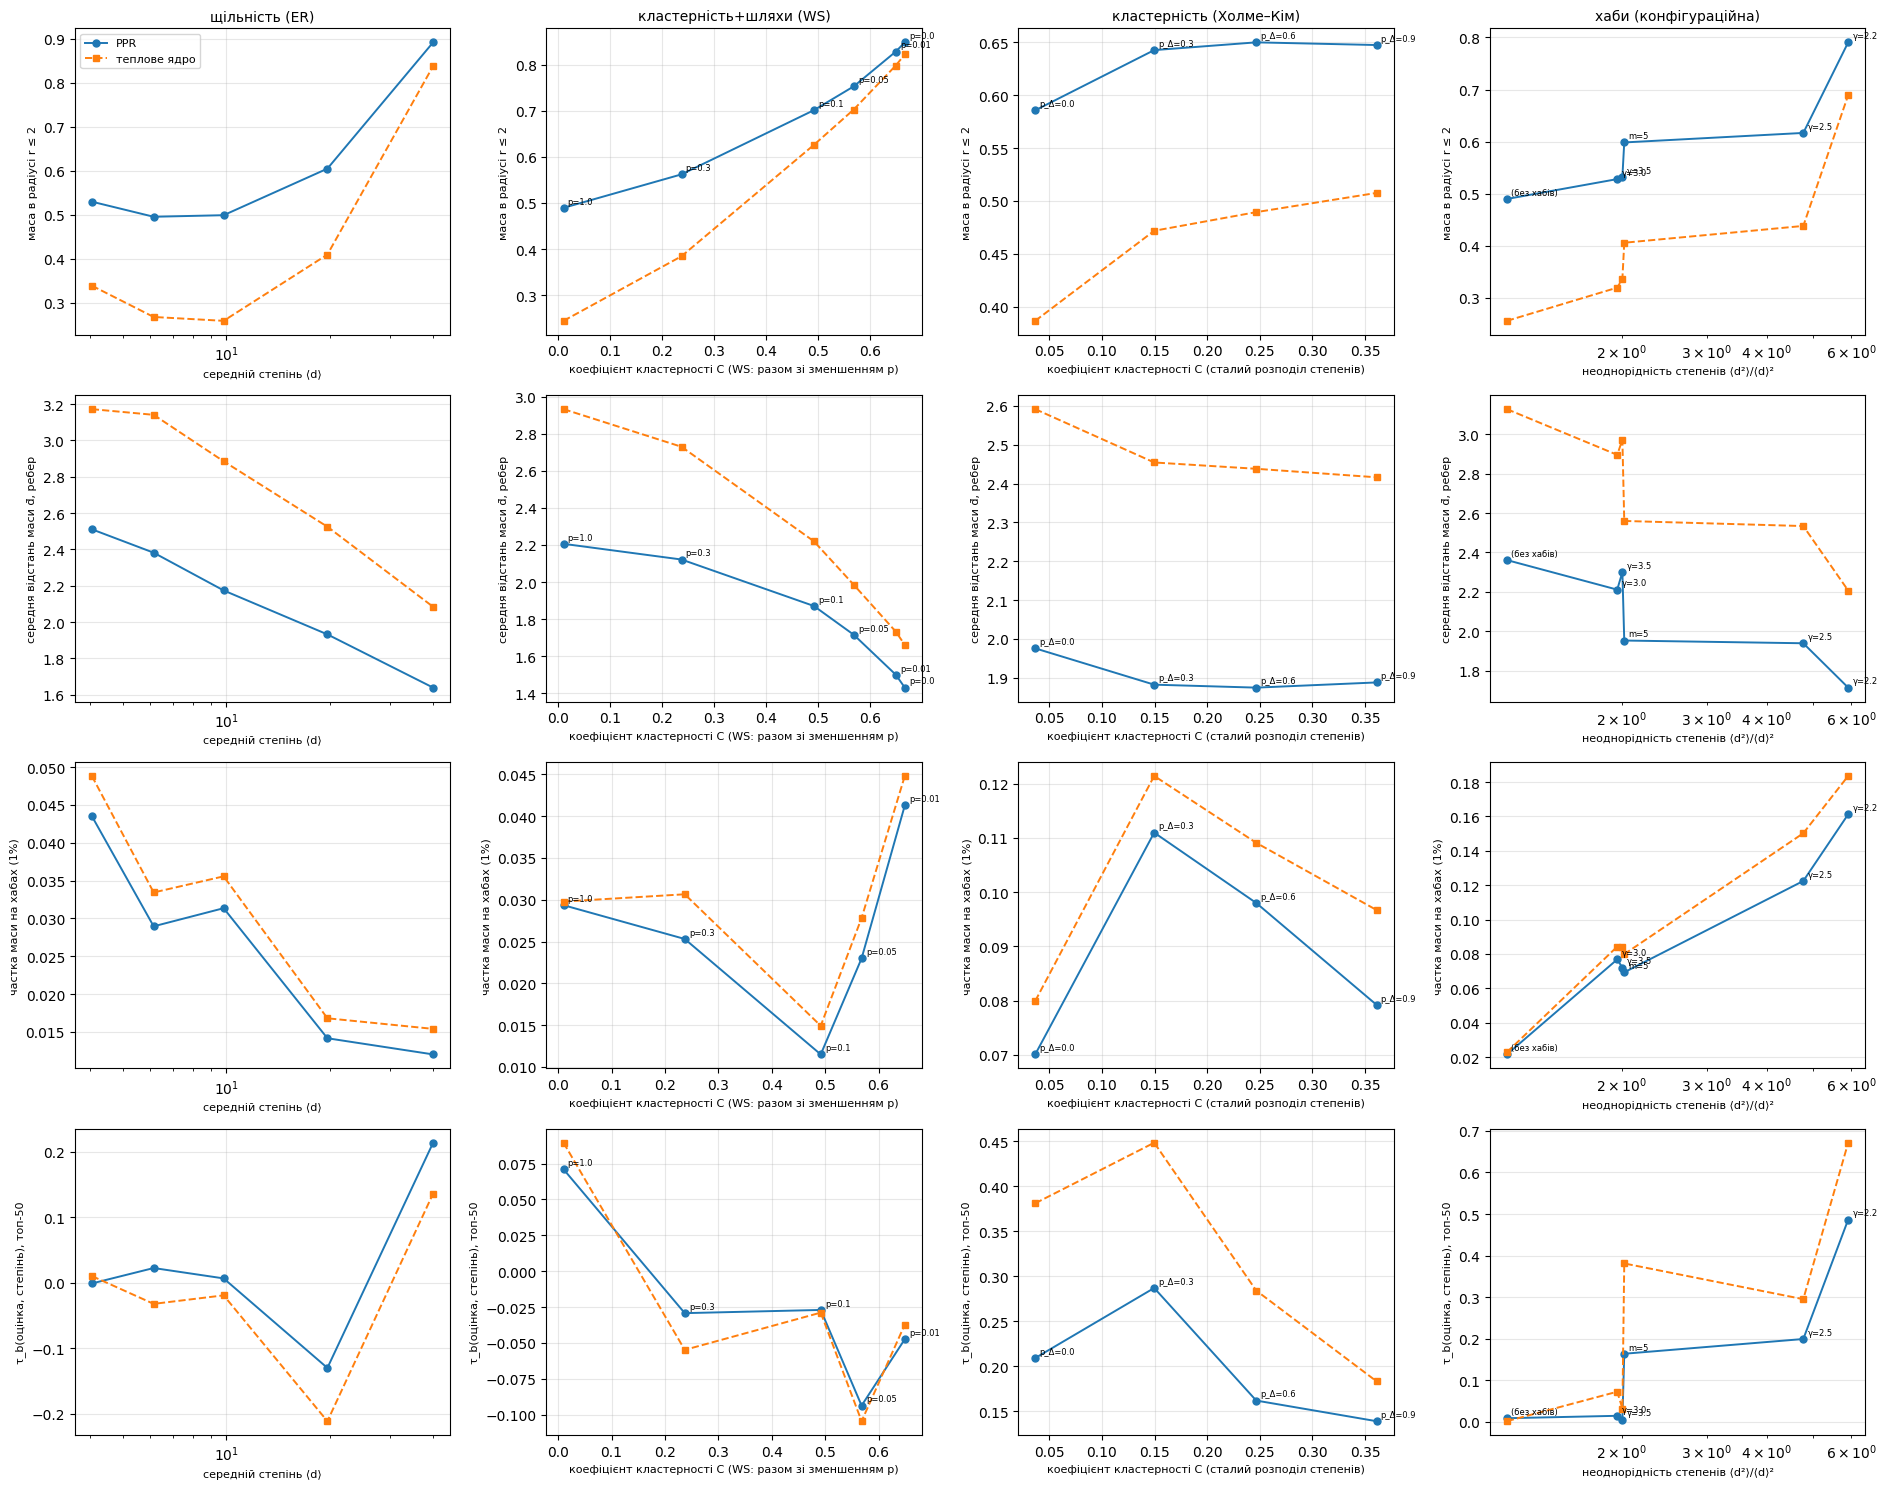

WS: C і ℓ змінюються разом:


,граф,C,ℓ
5,WS p=0.0,0.667,50.450
6,WS p=0.01,0.649,9.098
7,WS p=0.05,0.568,5.099
8,WS p=0.1,0.492,4.435
9,WS p=0.3,0.237,3.616
10,WS p=1.0,0.010,3.277


In [3]:
fams = [("щільність (ER)", "сер_степінь", "середній степінь ⟨d⟩", True),
        ("кластерність+шляхи (WS)", "C", "коефіцієнт кластерності C (WS: разом зі зменшенням p)", False),
        ("кластерність (Холме–Кім)", "C", "коефіцієнт кластерності C (сталий розподіл степенів)", False),
        ("хаби (конфігураційна)", "неоднорідність", "неоднорідність степенів ⟨d²⟩/⟨d⟩²", True)]
mets = [("маса_r_до_2", "маса в радіусі r ≤ 2"), ("сер_відстань", "середня відстань маси d̄, ребер"),
        ("маса_на_хабах", "частка маси на хабах (1%)"), ("τ_зі_степенем", "τ_b(оцінка, степінь), топ-50")]
fig, axs = plt.subplots(len(mets), len(fams), figsize=(19, 15))
for j, (fam, col, xl, logx) in enumerate(fams):
    for model, ls, mk in (("PPR", "-", "o"), ("теплове ядро", "--", "s")):
        sub = spread[(spread["сімейство"] == fam) & (spread["модель"] == model)].sort_values(col)
        for i, (m, ml) in enumerate(mets):
            ax = axs[i, j]
            ax.plot(sub[col], sub[m], ls, marker=mk, ms=5, lw=1.4, label=model)
            if model == "PPR" and fam != "щільність (ER)":
                for _, r in sub.iterrows():
                    ax.annotate(r["граф"].split(" ", 1)[1] if " " in r["граф"] else r["граф"], (r[col], r[m]),
                                fontsize=6, xytext=(3, 3), textcoords="offset points")
            ax.set_xlabel(xl, fontsize=8); ax.set_ylabel(ml, fontsize=8); ax.grid(alpha=0.3)
            if logx: ax.set_xscale("log")
    axs[0, j].set_title(fam, fontsize=10)
axs[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "03_struktura_poshyrennya.png", dpi=200); plt.show()

ws = tab_props[tab_props["сімейство"].str.startswith("кластерність+")][["граф", "C", "ℓ"]]
print("WS: C і ℓ змінюються разом:"); display(ws)

## Завдання 3.2. Дві ролі хаба

**1. Збирає масу.** Найпростіша ілюстрація — ланцюжок x–y–z з етапу 2 із запитом x. Центральний вузол y (степінь 2) при α = 0.15 отримує більше маси, ніж сам запит: з x блукання завжди переходить у y. Друга ілюстрація — зірка S_m із запитом у листку: центр отримує π_c = (1 − α)/(2 − α) ≈ 0.46 незалежно від m (формула (16)).

**2. Розпорошує свою масу.** Кожен з інших листків зірки отримує лише (1 − α)·π_c/m. Маса, що пройшла через хаб, ділиться на всіх його сусідів.

Перевіряємо обидві ролі аналітично і чисельно, а потім кількісно на графах:
- **збирання:** для вузлів на однаковій відстані від запиту оцінка PPR росте зі степенем, тож рахуємо нахил log π від log d;
- **розпорошення:** запит q з'єднаний із ціллю z через проміжний вузол h степеня D, тож π_z ∝ 1/D.

Ланцюжок, α = 0.15: π_x = 0.3453, π_y = 0.4595, π_z = 0.1953; π_y > π_x при α < 0.280
Зірка, α = 0.15: макс. |чисельне − формула (16)| = 3.6e-15
Зірка, α = 0.05: макс. |чисельне − формула (16)| = 1.3e-14
Розпорошення, α = 0.15: нахил log π_z від log D = -1.0000; макс. |π_z − формула| = 5.6e-17


Розпорошення, α = 0.05: нахил log π_z від log D = -1.0000; макс. |π_z − формула| = 4.2e-16


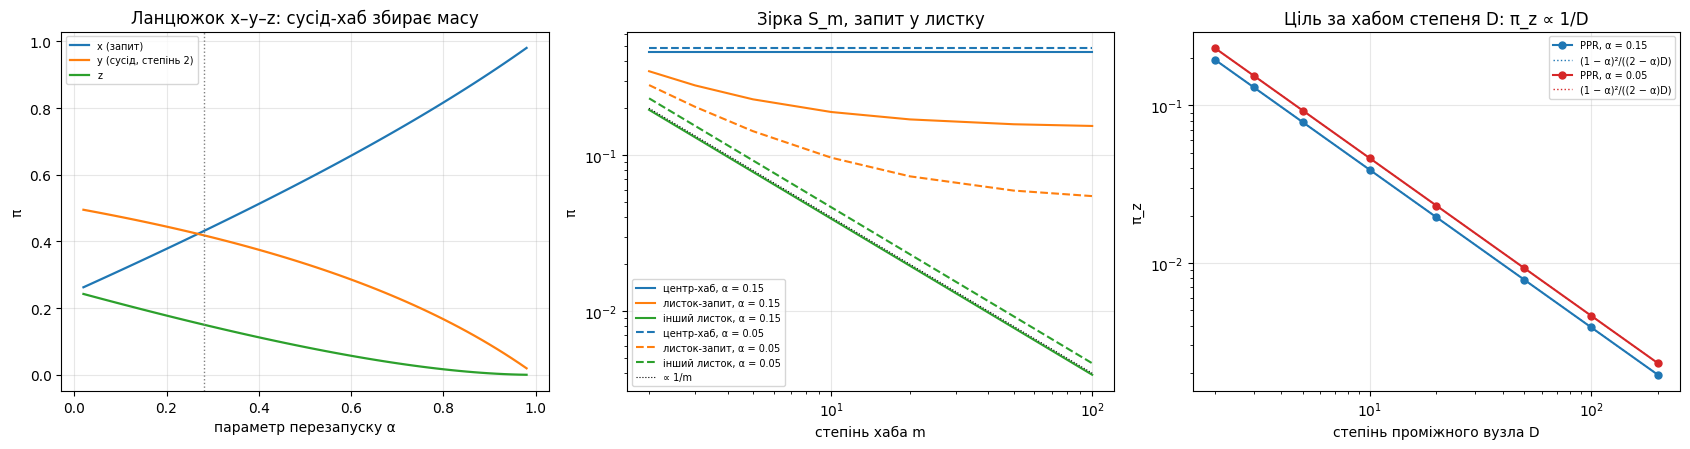

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.6))
g3 = nx.Graph([("x", "y"), ("y", "z")])
al = np.linspace(0.02, 0.98, 60)
P3 = np.array([rank(g3, "x", alpha=a).to_numpy() for a in al])
for k, lab in enumerate(("x (запит)", "y (сусід, степінь 2)", "z")):
    axs[0].plot(al, P3[:, k], lw=1.6, label=lab)
cross = al[np.argmax(P3[:, 0] > P3[:, 1])]
axs[0].axvline(cross, color="gray", ls=":", lw=1)
axs[0].set_title("Ланцюжок x–y–z: сусід-хаб збирає масу"); axs[0].set_xlabel("параметр перезапуску α"); axs[0].set_ylabel("π")
x015 = rank(g3, "x", alpha=0.15)
print(f"Ланцюжок, α = 0.15: π_x = {x015['x']:.4f}, π_y = {x015['y']:.4f}, π_z = {x015['z']:.4f}; "
      f"π_y > π_x при α < {cross:.3f}")

ms = np.array([2, 3, 5, 10, 20, 50, 100])
for a, ls in ((0.15, "-"), (0.05, "--")):
    num = np.array([rank(G.star(m), 1, alpha=a).to_numpy()[[0, 1, 2]] for m in ms])
    ana = np.array([A.star_ppr(m, a, leaf=1)[[0, 1, 2]] for m in ms])
    print(f"Зірка, α = {a}: макс. |чисельне − формула (16)| = {np.abs(num - ana).max():.1e}")
    axs[1].loglog(ms, num[:, 0], ls, color="C0", lw=1.5, label=f"центр-хаб, α = {a}")
    axs[1].loglog(ms, num[:, 1], ls, color="C1", lw=1.5, label=f"листок-запит, α = {a}")
    axs[1].loglog(ms, num[:, 2], ls, color="C2", lw=1.5, label=f"інший листок, α = {a}")
axs[1].loglog(ms, 0.4 / ms, "k:", lw=0.8, label="∝ 1/m")
axs[1].set_title("Зірка S_m, запит у листку"); axs[1].set_xlabel("степінь хаба m"); axs[1].set_ylabel("π")

# Розпорошення: q — h — z, h має ще D − 2 листків (степінь h = D)
Ds = np.array([2, 3, 5, 10, 20, 50, 100, 200])
for a, c in ((0.15, "C0"), (0.05, "C3")):
    pz = []
    for D in Ds:
        gd = nx.Graph([("q", "h"), ("h", "z")] + [("h", f"l{i}") for i in range(D - 2)])
        pz.append(rank(gd, "q", alpha=a)["z"])
    pz = np.array(pz)
    ana = (1 - a) ** 2 / ((2 - a) * Ds)          # формула (16): (1 − α)·π_c/m, m = D
    axs[2].loglog(Ds, pz, "o-", color=c, ms=5, label=f"PPR, α = {a}")
    axs[2].loglog(Ds, ana, ":", color=c, lw=1, label="(1 − α)²/((2 − α)D)")
    slope = np.polyfit(np.log(Ds), np.log(pz), 1)[0]
    print(f"Розпорошення, α = {a}: нахил log π_z від log D = {slope:.4f}; макс. |π_z − формула| = {np.abs(pz - ana).max():.1e}")
axs[2].set_title("Ціль за хабом степеня D: π_z ∝ 1/D"); axs[2].set_xlabel("степінь проміжного вузла D"); axs[2].set_ylabel("π_z")
for ax in axs: ax.grid(alpha=0.3); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "03_dvi_roli_haba.png", dpi=200); plt.show()

**Кількісно на графах.**
- **Збирання:** для вузлів на відстані 2 від запиту рахуємо нахил log π від log d. За оборотністю π_q(i) = d_i·π_i(q)/d_q, тож нахил ≈ 1 означає, що оцінка росте пропорційно степеню.
- **Розпорошення:** для вузлів на відстані 2 рахуємо також нахил log π від log(степеня найсильнішого проміжного сусіда). Від'ємний нахил означає, що маса, яка пройшла через хаб, ділиться на більше вузлів.

In [5]:
rows = []
for name in ["ER ⟨d⟩=10", "BA m=5", "конф. γ=2.2", "конф. γ=2.5", "конф. γ=3.0", "конф. γ=3.5", "ХК p_Δ=0.6", "MetaQA"]:
    g = GR[name]; nodes = list(g.nodes())
    for a in (0.15, 0.05):
        s_c, s_d = [], []
        for q in SEEDS[name]:
            x = rank(g, q, alpha=a)
            dd = nx.single_source_shortest_path_length(g, q, cutoff=2)
            r2 = [v for v, r in dd.items() if r == 2]
            if len(r2) < 10: continue
            dv = np.array([g.degree(v) for v in r2], dtype=float)
            # найбільший степінь серед спільних сусідів v і запиту (проміжний вузол шляху довжини 2)
            nq = set(g.neighbors(q))
            mid = np.array([max(g.degree(w) for w in set(g.neighbors(v)) & nq) for v in r2], dtype=float)
            pv = x[r2].to_numpy()
            if np.ptp(dv) > 0: s_c.append(np.polyfit(np.log(dv), np.log(pv), 1)[0])
            # частковий ефект проміжного вузла: регресія log π на log d_v і log d_mid
            if np.ptp(mid) > 0 and np.ptp(dv) > 0:
                Xr = np.column_stack([np.ones_like(dv), np.log(dv), np.log(mid)])
                s_d.append(np.linalg.lstsq(Xr, np.log(pv), rcond=None)[0][2])
        rows.append(dict(граф=name, α=a, нахил_від_власного_степеня=np.mean(s_c),
                         нахил_від_степеня_проміжного=np.mean(s_d) if s_d else np.nan, запитів=len(s_c)))
roles = pd.DataFrame(rows)
roles.to_csv(RES / "03_dvi_roli.csv", index=False)
display(roles)

,граф,α,нахил_від_власного_степеня,нахил_від_степеня_проміжного,запитів
0,ER ⟨d⟩=10,0.150,0.348,-0.637,20
1,ER ⟨d⟩=10,0.050,0.607,-0.386,20
2,BA m=5,0.150,0.679,-0.462,20
3,BA m=5,0.050,0.835,-0.259,20
4,конф. γ=2.2,0.150,0.805,-0.501,20
5,конф. γ=2.2,0.050,0.911,-0.311,20
6,конф. γ=2.5,0.150,0.557,-0.673,20
7,конф. γ=2.5,0.050,0.726,-0.485,20
8,конф. γ=3.0,0.150,0.393,-0.778,20
9,конф. γ=3.0,0.050,0.582,-0.598,20


## Завдання 3.3. Нормування за степенем

Для сирих оцінок, π/√d (симетричне нормування) і π/d (основне) рахуємо (вузол запиту виключено):
- частку хабів у топ-10 і топ-50;
- частку вузлів степеня 1 у топ-10;
- середню відстань топ-10 від запиту;
- τ_b зі степенем на топ-50.

Графи: сімейство конфігураційних моделей (γ), ER-еталон, BA, MetaQA. Основний розрахунок при α = 0.15 і t = 5.67. Повтор при α = 0.05: t для теплового ядра беремо як емпіричний оптимум t*(0.05) за методикою п. 2 (максимум τ_b на топ-50 з PPR(0.05)), а не H1, бо п. 2 показав, що при α < 0.1 H1 не працює.

In [6]:
NORM_GRAPHS = ["ER-еталон (без хабів)", "конф. γ=3.5", "конф. γ=3.0", "конф. γ=2.5", "конф. γ=2.2", "BA m=5", "MetaQA"]
NORMS = [(None, "сирі π"), ("sqrt_degree", "π/√d"), ("degree", "π/d")]

def t_star(g, seeds, alpha, ts):
    tau = np.zeros(len(ts))
    for q in seeds:
        xp = prep(rank(g, q, alpha=alpha).drop(index=q))
        for j, t in enumerate(ts):
            xh = prep(rank(g, q, "heat", t=t).drop(index=q))
            U = [i for i in np.union1d(topk_idx(xp, 50), topk_idx(xh, 50)) if xp[i] > 0 and xh[i] > 0]
            tau[j] += kendalltau(xp[U], xh[U]).statistic
    return ts[int(np.argmax(tau))], tau.max() / len(seeds)

TT = np.logspace(np.log10(2), np.log10(40), 25)
T005 = {}
for name in NORM_GRAPHS:
    T005[name] = t_star(GR[name], SEEDS[name][:10], 0.05, TT)
    print(f"{name:22s}: t*(α = 0.05) = {T005[name][0]:.2f} (τ_b = {T005[name][1]:.3f})")

ER-еталон (без хабів) : t*(α = 0.05) = 6.97 (τ_b = 0.796)


конф. γ=3.5           : t*(α = 0.05) = 8.94 (τ_b = 0.721)


конф. γ=3.0           : t*(α = 0.05) = 7.89 (τ_b = 0.775)


конф. γ=2.5           : t*(α = 0.05) = 6.97 (τ_b = 0.798)


конф. γ=2.2           : t*(α = 0.05) = 6.15 (τ_b = 0.866)


BA m=5                : t*(α = 0.05) = 6.15 (τ_b = 0.754)


MetaQA                : t*(α = 0.05) = 7.89 (τ_b = 0.707)


In [7]:
def norm_rows(name, alpha, t):
    g = GR[name]; nodes = list(g.nodes())
    deg = np.array([g.degree(v) for v in nodes], dtype=float)
    hub = deg >= np.quantile(deg, 0.99)
    out = []
    for q in SEEDS[name]:
        idx = nodes.index(q)
        dd = nx.single_source_shortest_path_length(g, q)
        dist = np.delete(np.array([dd.get(v, np.inf) for v in nodes], dtype=float), idx)
        ds, hs = np.delete(deg, idx), np.delete(hub, idx)
        for model, kw in (("PPR", dict(method="ppr", alpha=alpha)), ("теплове ядро", dict(method="heat", t=t))):
            for nz, nl in NORMS:
                x = prep(np.delete(rank(g, q, normalize=nz, **kw).to_numpy(), idx))
                T10, T50 = topk_idx(x, 10), topk_idx(x, 50)
                out.append(dict(граф=name, α=alpha, t=t, модель=model, нормування=nl,
                                хаби_в_топ10=hs[T10].mean(), хаби_в_топ50=hs[T50].mean(),
                                степінь1_в_топ10=(ds[T10] == 1).mean(), сер_відстань_топ10=dist[T10].mean(),
                                τ_зі_степенем=kendalltau(x[T50], ds[T50]).statistic))
    return out

rows = []
for name in NORM_GRAPHS:
    rows += norm_rows(name, ALPHA, T)
    rows += norm_rows(name, 0.05, T005[name][0])
norm = pd.DataFrame(rows).groupby(["граф", "α", "t", "модель", "нормування"], sort=False).mean().reset_index()
norm.to_csv(RES / "03_normuvannya.csv", index=False)
pd.set_option("display.float_format", "{:.3f}".format)
print("α = 0.15, t = 5.67:")
display(norm[norm["α"] == ALPHA].pivot_table(index=["граф", "модель"], columns="нормування",
        values=["хаби_в_топ10", "степінь1_в_топ10", "сер_відстань_топ10", "τ_зі_степенем"], sort=False))
print("α = 0.05, t = t*(0.05):")
display(norm[norm["α"] == 0.05].pivot_table(index=["граф", "модель"], columns="нормування",
        values=["хаби_в_топ10", "степінь1_в_топ10", "сер_відстань_топ10", "τ_зі_степенем"], sort=False))

α = 0.15, t = 5.67:


хаби_в_топ10             степінь1_в_топ10             сер_відстань_топ10             τ_зі_степенем              
нормування                               сирі π  π/√d   π/d           сирі π  π/√d   π/d             сирі π  π/√d   π/d        сирі π   π/√d    π/d
граф                  модель                                                                                                                       
ER-еталон (без хабів) PPR                 0.040 0.025 0.025            0.000 0.015 0.030              1.410 1.410 1.420         0.009 -0.126 -0.134
                      теплове ядро        0.045 0.025 0.015            0.000 0.015 0.040              1.415 1.415 1.460         0.002 -0.084 -0.091
конф. γ=3.5           PPR                 0.185 0.045 0.030            0.000 0.000 0.000              1.680 1.625 1.635         0.006 -0.075 -0.045
                      теплове ядро        0.210 0.040 0.000            0.000 0.000 0.000              1.720 1.700 1.770         0.032 -0.077 -0.041
конф. γ=3.0           PPR                 0.195 0.080 0.035            0.000 0.000 0.000              1.580 1.610 1.680         0.015 -0.081 -0.042
                      теплове ядро        0.260 0.075 0.005            0.000 0.000 0.000              1.665 1.680 1.810         0.073 -0.055 -0.071
конф. γ=2.5           PPR                 0.445 0.090 0.005            0.000 0.000 0.005              1.575 1.540 1.625         0.199 -0.112 -0.056
                      теплове ядро        0.565 0.160 0.000            0.000 0.000 0.005              1.655 1.575 1.760         0.295 -0.068 -0.059
конф. γ=2.2           PPR                 0.570 0.250 0.040            0.000 0.000 0.000              1.510 1.475 1.635         0.487  0.121  0.073
                      теплове ядро        0.765 0.455 0.000            0.000 0.000 0.000              1.685 1.550 1.840         0.672  0.274  0.035
BA m=5                PPR                 0.315 0.045 0.015            0.000 0.000 0.000              1.285 1.235 1.270         0.164 -0.205 -0.123
                      теплове ядро        0.570 0.155 0.000            0.000 0.000 0.000              1.580 1.275 1.330         0.381 -0.053 -0.096
MetaQA                PPR                 0.193 0.060 0.015            0.165 0.375 0.519              1.591 1.585 1.812        -0.006 -0.055  0.091
                      теплове ядро        0.214 0.054 0.010            0.127 0.385 0.587              1.718 1.635 1.931         0.074 -0.030  0.059

α = 0.05, t = t*(0.05):


хаби_в_топ10             степінь1_в_топ10             сер_відстань_топ10             τ_зі_степенем              
нормування                               сирі π  π/√d   π/d           сирі π  π/√d   π/d             сирі π  π/√d   π/d        сирі π   π/√d    π/d
граф                  модель                                                                                                                       
ER-еталон (без хабів) PPR                 0.055 0.025 0.025            0.000 0.015 0.030              1.410 1.410 1.425        -0.089 -0.158 -0.114
                      теплове ядро        0.045 0.025 0.010            0.000 0.010 0.040              1.425 1.420 1.475        -0.016 -0.076 -0.077
конф. γ=3.5           PPR                 0.325 0.070 0.020            0.000 0.000 0.000              1.820 1.645 1.670         0.084 -0.142 -0.038
                      теплове ядро        0.390 0.090 0.000            0.000 0.000 0.000              1.935 1.770 1.905         0.124 -0.068 -0.060
конф. γ=3.0           PPR                 0.465 0.125 0.025            0.000 0.000 0.000              1.800 1.615 1.730         0.304 -0.096 -0.058
                      теплове ядро        0.495 0.095 0.000            0.000 0.000 0.000              1.960 1.705 1.880         0.278 -0.088 -0.053
конф. γ=2.5           PPR                 0.645 0.320 0.005            0.000 0.000 0.005              1.710 1.545 1.650         0.475  0.065 -0.061
                      теплове ядро        0.675 0.290 0.000            0.000 0.000 0.005              1.780 1.600 1.810         0.447  0.035 -0.072
конф. γ=2.2           PPR                 0.765 0.500 0.025            0.000 0.000 0.000              1.640 1.505 1.670         0.721  0.437  0.064
                      теплове ядро        0.850 0.510 0.000            0.000 0.000 0.000              1.755 1.565 1.860         0.733  0.361  0.029
BA m=5                PPR                 0.535 0.270 0.015            0.000 0.000 0.000              1.475 1.280 1.275         0.459 -0.006 -0.119
                      теплове ядро        0.665 0.250 0.000            0.000 0.000 0.000              1.690 1.305 1.335         0.449 -0.017 -0.091
MetaQA                PPR                 0.317 0.078 0.009            0.115 0.393 0.553              1.818 1.610 1.868        -0.022 -0.108  0.061
                      теплове ядро        0.263 0.054 0.005            0.061 0.395 0.635              1.878 1.670 2.031         0.084 -0.023  0.062

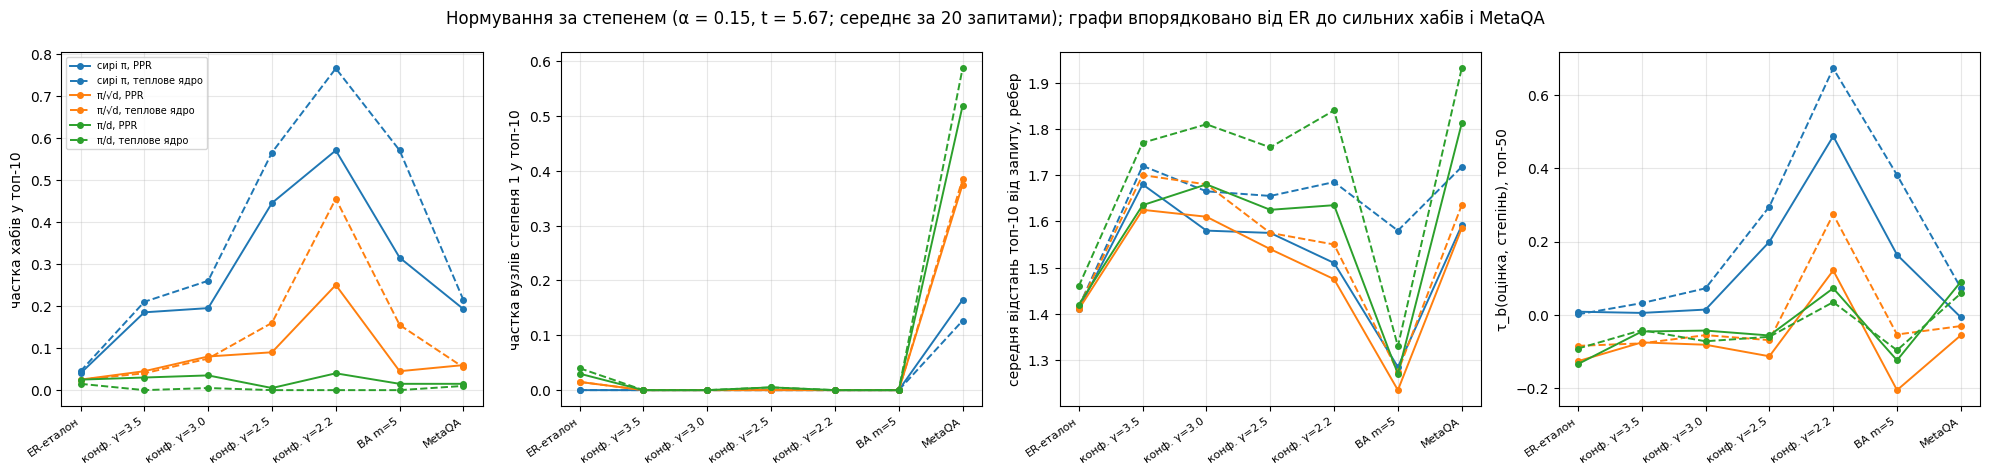

In [8]:
sub = norm[(norm["α"] == ALPHA)]
fig, axs = plt.subplots(1, 4, figsize=(20, 4.8))
xs = np.arange(len(NORM_GRAPHS))
for ax, (col, lab) in zip(axs, [("хаби_в_топ10", "частка хабів у топ-10"), ("степінь1_в_топ10", "частка вузлів степеня 1 у топ-10"),
                                ("сер_відстань_топ10", "середня відстань топ-10 від запиту, ребер"), ("τ_зі_степенем", "τ_b(оцінка, степінь), топ-50")]):
    for k, (nz, nl) in enumerate(NORMS):
        for model, ls in (("PPR", "-"), ("теплове ядро", "--")):
            v = [sub[(sub["граф"] == n) & (sub["модель"] == model) & (sub["нормування"] == nl)][col].item() for n in NORM_GRAPHS]
            ax.plot(xs, v, ls, marker="o", ms=4, color=f"C{k}", lw=1.4, label=f"{nl}, {model}")
    ax.set_xticks(xs); ax.set_xticklabels([n.replace(" (без хабів)", "") for n in NORM_GRAPHS], rotation=35, ha="right", fontsize=8)
    ax.set_ylabel(lab); ax.grid(alpha=0.3)
axs[0].legend(fontsize=7)
fig.suptitle("Нормування за степенем (α = 0.15, t = 5.67; середнє за 20 запитами); графи впорядковано від ER до сильних хабів і MetaQA")
plt.tight_layout(); plt.savefig(FIG / "03_normuvannya_haby.png", dpi=200); plt.show()

### MetaQA: які типи вузлів потрапляють у топ-10

Тип вузла визначаємо за атрибутом `kinds`. Для вузлів з кількома типами беремо тип за пріоритетом: фільм, людина, жанр, рік, мова, тег, imdb. Окремо дивимося медіанні ранги хабів Comedy і Drama.

тип                            фільм  людина  жанр   тег  imdb   рік  мова
α     модель       нормування                                             
0.150 PPR          сирі π      0.262   0.320 0.115 0.192 0.005 0.099 0.007
                   π/√d        0.243   0.404 0.040 0.233 0.005 0.075 0.000
                   π/d         0.162   0.487 0.025 0.264 0.005 0.054 0.003
      теплове ядро сирі π      0.326   0.283 0.133 0.154 0.005 0.090 0.008
                   π/√d        0.247   0.416 0.035 0.233 0.005 0.064 0.000
                   π/d         0.112   0.535 0.020 0.288 0.005 0.037 0.004
0.050 PPR          сирі π      0.252   0.268 0.235 0.152 0.005 0.081 0.008
                   π/√d        0.225   0.431 0.044 0.232 0.005 0.064 0.000
                   π/d         0.141   0.507 0.023 0.271 0.003 0.050 0.004
      теплове ядро сирі π      0.411   0.219 0.181 0.096 0.005 0.079 0.010
                   π/√d        0.252   0.429 0.035 0.230 0.005 0.050 0.000
                   π/d         0.090   0.538 0.015 0.318 0.005 0.030 0.005

ранг_Comedy  ранг_Drama
α     модель       нормування                         
0.150 PPR          сирі π           17.500      15.500
                   π/√d             67.000      60.500
                   π/d             510.000     613.500
      теплове ядро сирі π           12.000      16.500
                   π/√d             71.500      83.000
                   π/d             444.500     565.000
0.050 PPR          сирі π            6.000       6.500
                   π/√d             33.000      26.500
                   π/d             633.500     650.500
      теплове ядро сирі π           10.000       8.000
                   π/√d             62.000      57.500
                   π/d             529.500     628.000

Частки типів серед усіх вузлів MetaQA: {'людина': 0.512, 'тег': 0.281, 'фільм': 0.169, 'рік': 0.025, 'жанр': 0.007, 'мова': 0.005, 'imdb': 0.001}


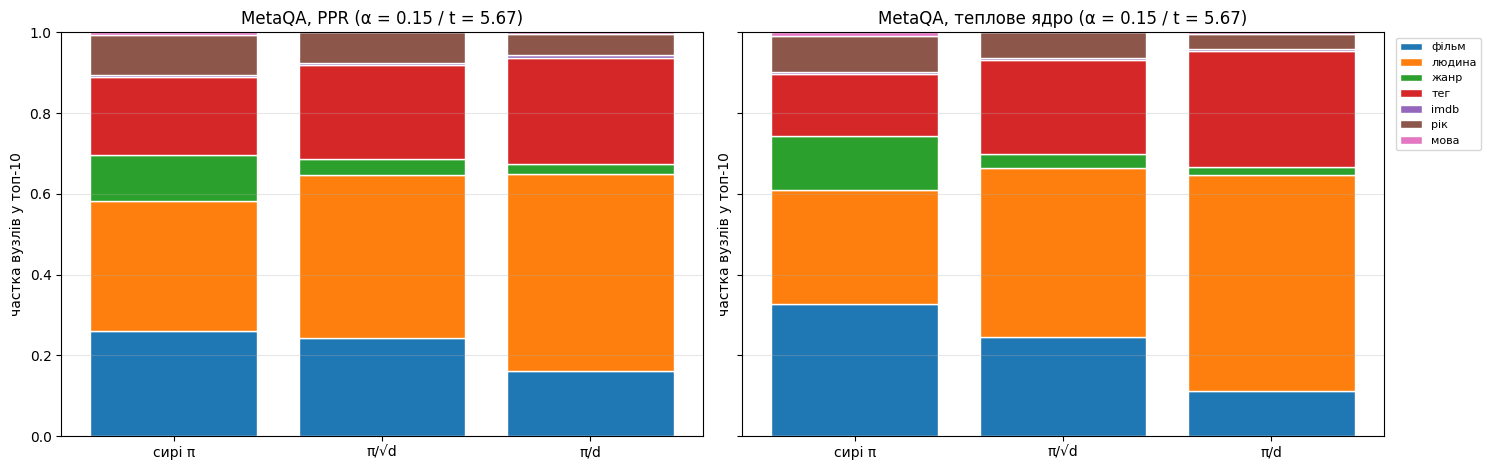

In [9]:
PRIOR = ["movie", "actor", "director", "writer", "genre", "year", "language", "tag", "imdb_rating", "imdb_votes"]
UA = {"movie": "фільм", "actor": "людина", "director": "людина", "writer": "людина", "genre": "жанр", "year": "рік",
      "language": "мова", "tag": "тег", "imdb_rating": "imdb", "imdb_votes": "imdb"}
g = GR["MetaQA"]; nodes = list(g.nodes())
kind = np.array([UA[min(g.nodes[v]["kinds"], key=PRIOR.index)] for v in nodes])
rows, ranks = [], []
for a, t in ((ALPHA, T), (0.05, T005["MetaQA"][0])):
    for q in SEEDS["MetaQA"]:
        idx = nodes.index(q); kk = np.delete(kind, idx); nn = [v for v in nodes if v != q]
        for model, kw in (("PPR", dict(method="ppr", alpha=a)), ("теплове ядро", dict(method="heat", t=t))):
            for nz, nl in NORMS:
                x = prep(np.delete(rank(g, q, normalize=nz, **kw).to_numpy(), idx))
                T10 = topk_idx(x, 10)
                for kname, c in pd.Series(kk[T10]).value_counts(normalize=True).items():
                    rows.append(dict(α=a, модель=model, нормування=nl, тип=kname, частка=c))
                order = np.argsort(-x, kind="stable")
                pos = {nn[i]: r + 1 for r, i in enumerate(order)}
                ranks.append(dict(α=a, модель=model, нормування=nl, ранг_Comedy=pos.get("Comedy"), ранг_Drama=pos.get("Drama")))
types = (pd.DataFrame(rows).groupby(["α", "модель", "нормування", "тип"], sort=False)["частка"].sum() / len(SEEDS["MetaQA"])).reset_index()
types.to_csv(RES / "03_metaqa_typy.csv", index=False)
tab_types = types.pivot_table(index=["α", "модель", "нормування"], columns="тип", values="частка", fill_value=0, sort=False)
display(tab_types)
display(pd.DataFrame(ranks).groupby(["α", "модель", "нормування"], sort=False).median())
print(f"Частки типів серед усіх вузлів MetaQA: {pd.Series(kind).value_counts(normalize=True).round(3).to_dict()}")

fig, axs = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, model in zip(axs, ("PPR", "теплове ядро")):
    sub = tab_types.loc[ALPHA].loc[model]
    bottom = np.zeros(len(sub))
    for c, col in enumerate(sub.columns):
        ax.bar(range(len(sub)), sub[col], bottom=bottom, color=f"C{c}", label=col, edgecolor="white", linewidth=1)
        bottom += sub[col].to_numpy()
    ax.set_xticks(range(len(sub))); ax.set_xticklabels(sub.index)
    ax.set_title(f"MetaQA, {model} (α = 0.15 / t = 5.67)"); ax.set_ylabel("частка вузлів у топ-10"); ax.grid(alpha=0.3, axis="y")
axs[1].legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.savefig(FIG / "03_metaqa_typy_top10.png", dpi=200); plt.show()

## Висновки

1. **Структура графа** (PPR, α = 0.15; теплове ядро, t = 5.67, поводиться так само).
   - Щільність стискає поширення за відстанню: на ER від ⟨d⟩ = 4 (найбільша компонента — 981 вузол) до ⟨d⟩ = 40 середня відстань маси падає з 2.51 до 1.64 ребра, а ефективна кількість вузлів зростає зі 134 до 459.
   - На WS кластерність і довжина шляхів падають разом (C з 0.667 до 0.010, ℓ з 50.5 до 3.28). Маса в радіусі 2 при цьому падає з 0.848 до 0.489, а ефективна кількість вузлів зростає з 28 до 325: висока кластерність утримує релевантність біля запиту.
   - Модель Холме–Кім відокремлює саму кластерність при сталому розподілі степенів. Ефект помірний і насичується: при зростанні C з 0.037 до 0.361 маса в радіусі 2 зростає з 0.586 до 0.648, а ефективна кількість вузлів падає з 269 до 202.
   - Хаби діють найсильніше. Від ER-еталону до конфігураційної моделі з γ = 2.2 частка маси на 1% найбільших вузлів зростає з 0.022 до 0.161, а τ_b оцінок зі степенем на топ-50 — з 0.009 до 0.487 (у теплового ядра до 0.672). Для γ = 2.2 очищення від петель і кратних ребер забрало 1728 з 7195 ребер, тож фактичний ⟨d⟩ = 10.9 замість заданих 14.4.
2. **Перша роль хаба — збирає масу.**
   - На ланцюжку x–y–z при α = 0.15 сусід y отримує 0.4595 маси, більше за сам запит x (0.3453). Це справджується для всіх α < 2 − √3 ≈ 0.268: π_y = (1 − α)/(2 − α), а з x блукання завжди переходить у y.
   - На зірці із запитом у листку центр отримує ту саму частку (1 − α)/(2 − α) незалежно від кількості листків m. Збіг з формулою (16) — до 10⁻¹⁴.
   - На графах оцінка вузлів на відстані 2 від запиту зростає зі степенем: нахил log π від log d становить від 0.21 до 0.91. Він більший при сильніших хабах і менших α (0.61–0.91 при α = 0.05) і прямує до 1 у межі d/Σd.
3. **Друга роль хаба — розпорошує свою масу.**
   - Маса, що пройшла через вузол степеня D, ділиться на всіх його сусідів: оцінка цілі за проміжним вузлом точно ∝ 1/D (нахил −1.0000, збіг з (1 − α)²/((2 − α)D) до 10⁻¹⁶).
   - На графах частковий нахил log π від log степеня проміжного вузла від'ємний: від −0.24 до −0.85.
   - Тобто хаб водночас висуває себе в топ і послаблює вузли, до яких веде. При сирих оцінках перша роль домінує: хаби займають 57% топ-10 PPR на γ = 2.2 і 77% у теплового ядра.
4. **Нормування за степенем.**
   - Нормування (а) π/d прибирає хаби з топу майже повністю. Частка хабів у топ-10 PPR при α = 0.15: γ = 2.2 — 0.570 → 0.040, BA — 0.315 → 0.015, MetaQA — 0.193 → 0.015. τ_b зі степенем знижується до |τ_b| ≤ 0.14 на всіх графах.
   - Нормування (б) π/√d (симетрична матриця) дає проміжний результат: 0.250, 0.045 і 0.060 відповідно.
   - При α = 0.05 роль хабів у сирих оцінках сильніша: 0.765 (γ = 2.2), 0.535 (BA), 0.465 (γ = 3.0 проти 0.195 при α = 0.15). А π/d і тут лишає ≤ 0.025 хабів у топ-10 PPR і ≤ 0.01 у теплового ядра.
5. **Ціна нормування π/d — перекорекція в бік вузлів малого степеня.**
   - На MetaQA частка вузлів степеня 1 у топ-10 зростає з 0.165 (сирі) до 0.375 (π/√d) і 0.519 (π/d) для PPR, а для теплового ядра — з 0.127 до 0.587. Це переважно люди й теги з одним фільмом.
   - Склад топ-10 PPR змінюється так: жанри 0.115 → 0.025, фільми 0.262 → 0.162, люди 0.320 → 0.487, теги 0.192 → 0.264. Медіанний ранг Comedy змінюється з 17.5 до 67 (π/√d) і 510 (π/d).
   - На синтетичних графах із мінімальним степенем ≥ 3 такої перекорекції немає. На ER-еталоні нормовані оцінки мають слабку від'ємну кореляцію зі степенем (τ_b від −0.08 до −0.16 для π/d і π/√d при обох α).
   - Отже, π/d — правильний засіб проти хабів, а π/√d — компроміс. Чи покращує нормування якість ранжування на MetaQA, де самі відповіді часто є вузлами малого степеня, перевіримо в п. 6.